In [ ]:
# Day 01: Titanic Survival Prediction
Goal: predict which passengers survived, and find out what sorts of people were more likely to survive.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
from xgboost import XGBClassifier

print("All libraries loaded!")



All libraries loaded!


In [2]:
df = pd.read_csv("train.csv")
print("Rows and columns: ", df.shape)
df.head()

Rows and columns:  (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()
print("\nMissing value in each column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Missing value in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2

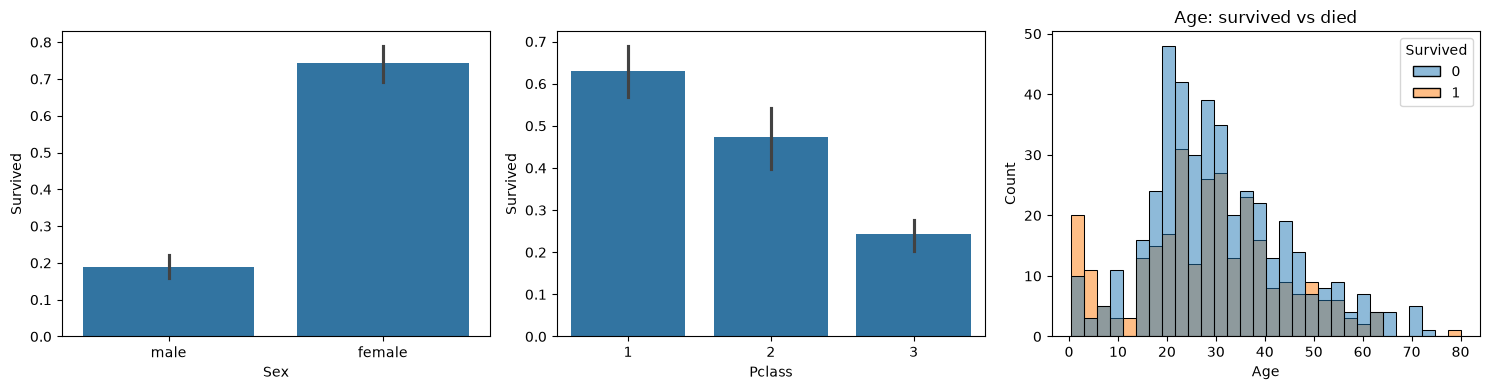

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0])

sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1])

sns.histplot(data=df, x="Age", hue="Survived", bins=30, ax=axes[2])
axes[2].set_title("Age: survived vs died")

plt.tight_layout()
plt.show()


In [ ]:
## EDA Findings
- Women survived much more than men (about 74% vs 19%).
- 1st class passengers survived more than 3rd class.
- Young children had a higher survival rate.

In [11]:
data = df.copy()   # work on a copy so the original stays safe

# 1. TITLE: pull "Mr", "Mrs", "Miss" etc. out of the name
#    e.g. "Braund, Mr. Owen Harris" -> "Mr"
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")
data["Title"] = data["Title"].replace(["Mlle", "Ms"], "Miss").replace("Mme", "Mrs")
common = ["Mr", "Mrs", "Miss", "Master"]
data["Title"] = data["Title"].where(data["Title"].isin(common), "Rare")

# 2. AGE: fill missing ages with the median age of people with the same title
data["Age"] = data["Age"].fillna(data.groupby("Title")["Age"].transform("median"))

# 3. CABIN: too much is missing, so just record "had a cabin or not"
data["HasCabin"] = data["Cabin"].notnull().astype(int)

# 4. FAMILY SIZE: siblings/spouses + parents/children + yourself
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1

# 5. Split into inputs (X) and the answer (y)
y = data["Survived"]
X = data.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])

print("Missing Age now:", X["Age"].isnull().sum())
print(data["Title"].value_counts())
X.head()

Missing Age now: 0
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,HasCabin,FamilySize
0,3,male,22.0,1,0,7.2500,S,Mr,0,2
1,1,female,38.0,1,0,71.2833,C,Mrs,1,2
2,3,female,26.0,0,0,7.9250,S,Miss,0,1
3,1,female,35.0,1,0,53.1000,S,Mrs,1,2
4,3,male,35.0,0,0,8.0500,S,Mr,0,1


In [ ]:
## Preprocessing
- Age:filled with median age per Title (Mr, Mrs, Miss, Master), more accurate than one overall median.
- Cabin:77% missing, converted to HasCabin (1/0) instead of guessing.
- New features: Title, FamilySize.
- Embarked (2 missing) will be filled inside the Pipeline.

In [12]:
num_cols = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]
cat_cols = ["Sex", "Pclass", "Embarked", "Title", "HasCabin"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

print("Preprocessing pipeline ready!")

Preprocessing pipeline ready!


In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             random_state=42, eval_metric="logloss"),
}

print("Models ready:", list(models.keys()))

Models ready: ['Logistic Regression', 'Random Forest', 'XGBoost']


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
for name, model in models.items():
    pipe = Pipeline([("pre", preprocess), ("model", model)])
    scores = cross_validate(pipe, X, y, cv=cv, scoring=["accuracy", "f1"])
    results.append({
        "Model": name,
        "Accuracy (mean)": round(scores["test_accuracy"].mean(), 3),
        "Accuracy (std)": round(scores["test_accuracy"].std(), 3),
        "F1": round(scores["test_f1"].mean(), 3),
    })

results_df = pd.DataFrame(results).sort_values("Accuracy (mean)", ascending=False)
results_df

,Model,Accuracy (mean),Accuracy (std),F1
2,XGBoost,0.844,0.015,0.787
0,Logistic Regression,0.832,0.016,0.774
1,Random Forest,0.813,0.008,0.753


In [ ]:
## Model Comparison (5-Fold Cross-Validation)
Each model was trained on 4/5 of the data and tested on the remaining 1/5, 
repeated 5 times.
    The table shows the average scores.

Best model: XGBoost


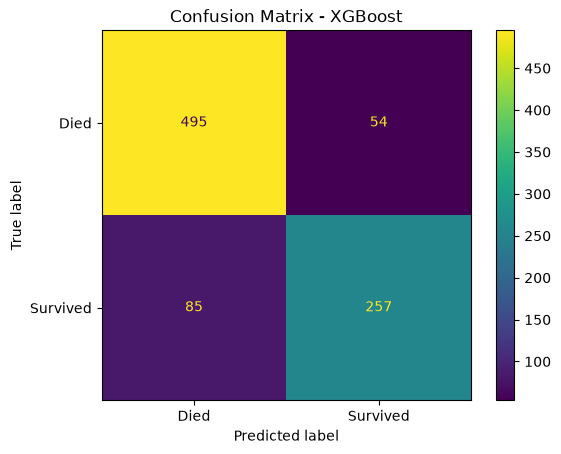

In [16]:
# Pick the model that came top in the results table
best_name = results_df.iloc[0]["Model"]
print("Best model:", best_name)

# Join cleaning + best model
best = Pipeline([("pre", preprocess), ("model", models[best_name])])

# Get a prediction for every passenger (using the same 5-group testing)
pred = cross_val_predict(best, X, y, cv=cv)

# Draw the report card
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Died", "Survived"])
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

In [ ]:
## Confusion Matrix (XGBoost)
- Correctly predicted deaths: 495 / 549 (90%)
- Correctly predicted survivors: 257 / 342 (75%)
- Overall accuracy: 752 / 891 = 84.4%
- Most common mistake: 85 survivors were predicted as died. The model is better at spotting deaths than survivors.

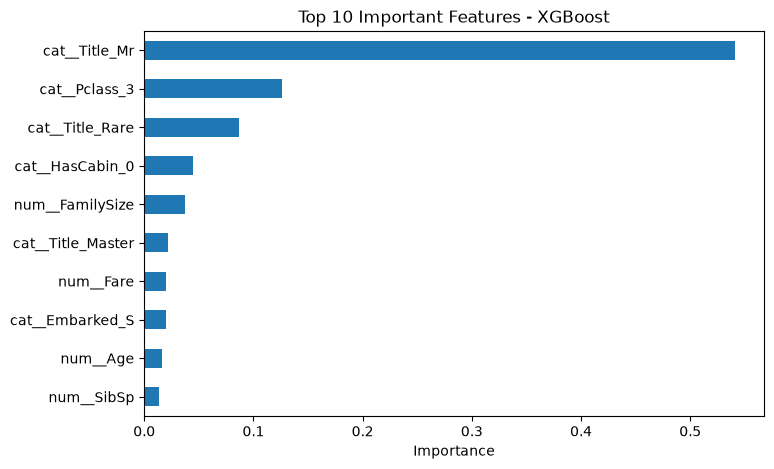

In [17]:
# Train the best model on all the data
best.fit(X, y)

# Get the names of the columns after cleaning (e.g. Sex_male, Title_Mr)
names = best.named_steps["pre"].get_feature_names_out()

# Get how important each column was to the model
importance = pd.Series(best.named_steps["model"].feature_importances_, index=names)

# Show the top 10 as a bar chart
importance.sort_values().tail(10).plot(kind="barh", figsize=(8, 5))
plt.title(f"Top 10 Important Features - {best_name}")
plt.xlabel("Importance")
plt.show()

In [ ]:
## Feature Importance (XGBoost)
- Title_Mris by far the most important feature: adult men had the lowest survival ("women and children first").
- Pclass_3 and **HasCabin_0** show that poorer passengers survived less.
- Title_Master (young boys) and **FamilySize** also mattered.
- Sex does not appear in the top 10 because Title_Mr already captures the same information (adult male), so the model relied on Title instead.

In [18]:
## Conclusion

Results (5-fold cross-validation):

Best model: XGBoost, about 84% accuracy (752 of 891 passengers predicted correctly).

Who survived? Women, children (Title "Master") and 1st class passengers were much more likely to survive. Adult men (Title "Mr") and 3rd class passengers had the lowest survival.

Why XGBoost won: it builds trees one after another, each fixing the previous mistakes, so it captures patterns like "3rd class AND adult male" better than a single straight line (Logistic Regression).

Weakness:the model misses some survivors (85 predicted as died). It is better at spotting deaths than survivors.

Next improvement: tune XGBoost settings with GridSearchCV, or add features like ticket group size.

SyntaxError: invalid decimal literal (621328767.py, line 12)